# 1 · Corpus, análisis exploratorio y preprocesado

Práctica final · **Asistente de agenda en lenguaje natural** · Procesamiento del Lenguaje Natural

Poned en la misma carpeta este notebook, `utilidades.py`, `evaluar.py`, `train.jsonl` y `agenda.jsonl`. Las celdas marcadas con `# TODO` son las que tenéis que completar.

In [1]:
from utilidades import cargar, guardar, anotar, comprobar, trozos_repetidos, normalizar, INTENCIONES, TIPOS, DIFICULTADES
from collections import Counter
import os, re
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("datos", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
pd.set_option("display.max_colwidth", 120)

train = cargar("train.jsonl")
agenda = cargar("agenda.jsonl")
AG = {a["id"]: a for a in agenda}
print(len(train), "frases ·", len(agenda), "entradas en la agenda")

150 frases · 30 entradas en la agenda


## 1.1 Ampliación del corpus
Añadid al menos 100 frases propias con las convenciones de etiquetado del enunciado. Usad ids propios (`g001`, `g002`…) y marcad con `dificil=True` las que tengan faltas, abreviaturas, negaciones, etc.

**Criterios que hemos seguido**

* `train.jsonl` no tiene ninguna frase difícil y el experimento E3 pide **≥30 difíciles en validación**. Con un 20 % de validación estratificada eso exige ≥150 difíciles en total, así que escribimos **235 frases propias, 156 difíciles**, repartidas entre las 8 intenciones y reforzando las menos representadas en `train` (`borrar`, `completar`, `modificar`, `otro`).
* Cada frase difícil lleva un campo propio `dificultad` (que `evaluar.py` ignora) con su tipo principal, para desglosar E3: `ortografia`, `abreviatura` (lenguaje de mensajería), `mayusculas`, `negacion`, `fecha_relativa` («dentro de tres días», «el lunes que viene», intervalos), `numeros_letras` («a las cinco»), `larga` (muchas entidades), `fuera_dominio` (`otro` que se parece al dominio: «¿qué tiempo hará el sábado?»), `parafrasis` (sin palabras en común con la agenda: «lo de los dientes» → Dentista) y `contexto` (la hora depende del contexto: «cena a las 9» → 21:00).
* Para `buscar`, `completar`, `modificar` y `borrar` la `ref` apunta a una entrada real de `agenda.jsonl` (y en `completar`, siempre a una **tarea**).
* Convenciones que hemos tenido que decidir copiando lo que hace `train.jsonl`:
  * «antes del viernes» → FECHA = «del viernes»; en `modificar`, «al viernes» → FECHA = «viernes» (como `tr109`).
  * «el martes por la tarde» → solo FECHA; la franja vaga no es HORA (como `tr059`).
  * «cita en la peluquería» o «en casa de mi madre» no se anotan como LUGAR (como `tr007`, `tr012`).
  * En PERSONA, los parentescos sin posesivo («mi primo Dani» → «Dani»; «su hermana» → «hermana»).
  * Fechas negadas («no es el miércoles, es el jueves»): se anotan **todas** las menciones, porque la tarea B es reconocer menciones; decidir cuál es el valor nuevo le corresponde al asistente.
  * «del 16 al 20» → intervalo `2026-02-16/2026-02-20`; «dentro de dos semanas» → `2026-02-23`.
* Las frases son nuestras (no copias de `train`): comprobamos que ninguna coincide con una de `train` al pasar a minúsculas, para que no haya fugas entre entrenamiento y validación.

In [2]:
# Cada frase: (texto, intención, entidades, ref, dificultad). dificultad=None → frase normal.
# Calendario de referencia (hoy = lunes 9): ma 10 · mi 11 · ju 12 · vi 13 · sá 14 · do 15 · lu 16 · ma 17 · mi 18 · ju 19 · vi 20 · sá 21 · lu 23
# Criterio para fechas negadas («no es el miércoles, es el jueves»): se anotan todas las menciones (NER marca menciones, no su polaridad).
F = lambda texto, intencion, ents=(), ref=None, dif=None: (texto, intencion, list(ents), ref, dif)

frases = [
    # ---------------- crear_evento ----------------
    F("El miércoles a las 6 tengo fisio en la clínica Vitalia", "crear_evento",
      [("El miércoles", "FECHA", "2026-02-11"), ("a las 6", "HORA", "18:00"), ("clínica Vitalia", "LUGAR")]),
    F("Apunta una reunión con Javier el jueves de la semana que viene a las 11 en el despacho 3204", "crear_evento",
      [("Javier", "PERSONA"), ("el jueves de la semana que viene", "FECHA", "2026-02-19"), ("a las 11", "HORA", "11:00"), ("despacho 3204", "LUGAR")]),
    F("Mañana como con mi padre a la una y media en el bar de la facultad", "crear_evento",
      [("Mañana", "FECHA", "2026-02-10"), ("padre", "PERSONA"), ("a la una y media", "HORA", "13:30"), ("bar de la facultad", "LUGAR")], dif="numeros_letras"),
    F("el viernes a las cinco tengo tutoría de Álgebra con García", "crear_evento",
      [("el viernes", "FECHA", "2026-02-13"), ("a las cinco", "HORA", "17:00"), ("Álgebra", "ASIGNATURA", "Álgebra"), ("García", "PERSONA")], dif="numeros_letras"),
    F("mñn a las 10 tngo examen d PLN en el aula 1205", "crear_evento",
      [("mñn", "FECHA", "2026-02-10"), ("a las 10", "HORA", "10:00"), ("PLN", "ASIGNATURA", "PLN"), ("aula 1205", "LUGAR")], dif="abreviatura"),
    F("q el sabado a las 9 ceno con lucia", "crear_evento",
      [("el sabado", "FECHA", "2026-02-14"), ("a las 9", "HORA", "21:00"), ("lucia", "PERSONA")], dif="abreviatura"),
    F("TENGO DENTISTA EL MARTES 17 A LAS 9 Y MEDIA", "crear_evento",
      [("EL MARTES 17", "FECHA", "2026-02-17"), ("A LAS 9 Y MEDIA", "HORA", "09:30")], dif="mayusculas"),
    F("Dentro de tres días tengo la entrevista de prácticas a las doce en la sede de Indra", "crear_evento",
      [("Dentro de tres días", "FECHA", "2026-02-12"), ("a las doce", "HORA", "12:00"), ("sede de Indra", "LUGAR")], dif="fecha_relativa"),
    F("pasado mañana a mediodía comida con Andrea y Carlos en el Vips", "crear_evento",
      [("pasado mañana", "FECHA", "2026-02-11"), ("a mediodía", "HORA", "14:00"), ("Andrea", "PERSONA"), ("Carlos", "PERSONA"), ("Vips", "LUGAR")], dif="fecha_relativa"),
    F("El lunes que viene a las 8 de la mañana tengo análisis de sangre en el centro de salud", "crear_evento",
      [("El lunes que viene", "FECHA", "2026-02-16"), ("a las 8 de la mañana", "HORA", "08:00"), ("centro de salud", "LUGAR")], dif="fecha_relativa"),
    F("Quedada con mi hermana el domingo a las 7 en la plaza Mayor", "crear_evento",
      [("hermana", "PERSONA"), ("el domingo", "FECHA", "2026-02-15"), ("a las 7", "HORA", "19:00"), ("plaza Mayor", "LUGAR")]),
    F("Apúntame que el jueves de la semana que viene a las diez y media tengo reunión con Elena y Javier en el despacho 4012 para hablar del TFG, y es importante", "crear_evento",
      [("el jueves de la semana que viene", "FECHA", "2026-02-19"), ("a las diez y media", "HORA", "10:30"), ("Elena", "PERSONA"), ("Javier", "PERSONA"),
       ("despacho 4012", "LUGAR"), ("TFG", "ASIGNATURA", "TFG"), ("es importante", "PRIORIDAD", "alta")], dif="larga"),
    F("reunion de grupo de redes el miercoles a las 4 en la biblio", "crear_evento",
      [("redes", "ASIGNATURA", "Redes"), ("el miercoles", "FECHA", "2026-02-11"), ("a las 4", "HORA", "16:00"), ("biblio", "LUGAR")], dif="ortografia"),
    F("El 2 de marzo a las 9 tengo el examen final de Bases de Datos en el aula magna", "crear_evento",
      [("El 2 de marzo", "FECHA", "2026-03-02"), ("a las 9", "HORA", "09:00"), ("Bases de Datos", "ASIGNATURA", "Bases de Datos"), ("aula magna", "LUGAR")]),
    F("Hoy a las 8 de la tarde voy al gimnasio con Pablo", "crear_evento",
      [("Hoy", "FECHA", "2026-02-09"), ("a las 8 de la tarde", "HORA", "20:00"), ("gimnasio", "LUGAR"), ("Pablo", "PERSONA")]),
    F("El sábado salgo de fiesta con Marta a las 11 de la noche", "crear_evento",
      [("El sábado", "FECHA", "2026-02-14"), ("Marta", "PERSONA"), ("a las 11 de la noche", "HORA", "23:00")]),
    F("Cena de empresa el viernes 20 a las 9 en el restaurante Lhardy", "crear_evento",
      [("el viernes 20", "FECHA", "2026-02-20"), ("a las 9", "HORA", "21:00"), ("restaurante Lhardy", "LUGAR")], dif="contexto"),
    F("Ojo, que mañana tengo el oculista a las cuatro menos cuarto", "crear_evento",
      [("mañana", "FECHA", "2026-02-10"), ("a las cuatro menos cuarto", "HORA", "15:45")], dif="numeros_letras"),
    F("No es el jueves, es el viernes: apunta el partido de pádel con Carlos a las 6", "crear_evento",
      [("el jueves", "FECHA", "2026-02-12"), ("el viernes", "FECHA", "2026-02-13"), ("Carlos", "PERSONA"), ("a las 6", "HORA", "18:00")], dif="negacion"),
    F("Mi madre viene a verme el domingo a la hora de comer", "crear_evento",
      [("madre", "PERSONA"), ("el domingo", "FECHA", "2026-02-15")]),
    F("porfa apunta cita en el oculista el 24 a las 5 y cuarto", "crear_evento",
      [("el 24", "FECHA", "2026-02-24"), ("a las 5 y cuarto", "HORA", "17:15")], dif="abreviatura"),
    F("Este viernes a las 7 y media de la tarde hay cine con los de clase en el Kinépolis", "crear_evento",
      [("Este viernes", "FECHA", "2026-02-13"), ("a las 7 y media de la tarde", "HORA", "19:30"), ("Kinépolis", "LUGAR")]),
    F("tng q ir al medico el jueves a las 9 menos cuarto", "crear_evento",
      [("el jueves", "FECHA", "2026-02-12"), ("a las 9 menos cuarto", "HORA", "08:45")], dif="abreviatura"),
    F("Videollamada con la abuela el domingo a las 6 de la tarde", "crear_evento",
      [("abuela", "PERSONA"), ("el domingo", "FECHA", "2026-02-15"), ("a las 6 de la tarde", "HORA", "18:00")]),
    F("EL MIÉRCOLES DE LA SEMANA QUE VIENE TENGO LA PRESENTACIÓN DE PLN A LAS 3", "crear_evento",
      [("EL MIÉRCOLES DE LA SEMANA QUE VIENE", "FECHA", "2026-02-18"), ("PLN", "ASIGNATURA", "PLN"), ("A LAS 3", "HORA", "15:00")], dif="mayusculas"),
    F("Dentro de una semana a las 10 tengo la revisión del coche en el taller de la calle Alcalá", "crear_evento",
      [("Dentro de una semana", "FECHA", "2026-02-16"), ("a las 10", "HORA", "10:00"), ("taller de la calle Alcalá", "LUGAR")], dif="fecha_relativa"),
    F("mañana x la tarde a las 5 entreno d baloncesto en el poli", "crear_evento",
      [("mañana", "FECHA", "2026-02-10"), ("a las 5", "HORA", "17:00"), ("poli", "LUGAR")], dif="abreviatura"),
    F("Desayuno con Elena el martes a las 9 en la cafetería de la facultad", "crear_evento",
      [("Elena", "PERSONA"), ("el martes", "FECHA", "2026-02-10"), ("a las 9", "HORA", "09:00"), ("cafetería de la facultad", "LUGAR")]),
    F("el 27 de febrero a las veinte treinta concierto de Vetusta en la Riviera", "crear_evento",
      [("el 27 de febrero", "FECHA", "2026-02-27"), ("a las veinte treinta", "HORA", "20:30"), ("la Riviera", "LUGAR")], dif="numeros_letras"),
    F("Reunión de Estadística con el profe el lunes a las 12 en el seminario 2", "crear_evento",
      [("Estadística", "ASIGNATURA", "Estadística"), ("el lunes", "FECHA", "2026-02-16"), ("a las 12", "HORA", "12:00"), ("seminario 2", "LUGAR")]),
    F("El miércoles a las nueve de la noche tengo videollamada con Carlos, que no se me olvide", "crear_evento",
      [("El miércoles", "FECHA", "2026-02-11"), ("a las nueve de la noche", "HORA", "21:00"), ("Carlos", "PERSONA")], dif="numeros_letras"),
    F("Apunta: cumple de mi primo Dani el sábado de la semana que viene a las 8 en el Burger de Moncloa", "crear_evento",
      [("Dani", "PERSONA"), ("el sábado de la semana que viene", "FECHA", "2026-02-21"), ("a las 8", "HORA", "20:00"), ("Burger de Moncloa", "LUGAR")], dif="contexto"),

    # ---------------- crear_tarea ----------------
    F("Tengo que hacer la práctica 2 de Redes para el jueves de la semana que viene", "crear_tarea",
      [("Redes", "ASIGNATURA", "Redes"), ("el jueves de la semana que viene", "FECHA", "2026-02-19")]),
    F("Recuérdame llamar a mi tía mañana", "crear_tarea",
      [("tía", "PERSONA"), ("mañana", "FECHA", "2026-02-10")]),
    F("Hay que comprar el billete de tren antes del viernes, corre prisa", "crear_tarea",
      [("del viernes", "FECHA", "2026-02-13"), ("corre prisa", "PRIORIDAD", "alta")]),
    F("Tengo pendiente escribirle un correo a Javier sobre la nota de PLN", "crear_tarea",
      [("Javier", "PERSONA"), ("PLN", "ASIGNATURA", "PLN")]),
    F("Apunta que tengo que mirar pisos para el curso que viene, sin prisa", "crear_tarea",
      [("sin prisa", "PRIORIDAD", "baja")]),
    F("Nueva tarea: imprimir el TFG antes del 27", "crear_tarea",
      [("TFG", "ASIGNATURA", "TFG"), ("del 27", "FECHA", "2026-02-27")]),
    F("tng q estudiar bbdd pa el lunes", "crear_tarea",
      [("bbdd", "ASIGNATURA", "Bases de Datos"), ("el lunes", "FECHA", "2026-02-16")], dif="abreviatura"),
    F("recuerdame q tngo q comprar pan hoy", "crear_tarea",
      [("hoy", "FECHA", "2026-02-09")], dif="abreviatura"),
    F("hay q mandar el trabajo d estadistica antes del miercoles, es urgente", "crear_tarea",
      [("estadistica", "ASIGNATURA", "Estadística"), ("del miercoles", "FECHA", "2026-02-11"), ("es urgente", "PRIORIDAD", "alta")], dif="abreviatura"),
    F("TENGO QUE ENTREGAR EL INFORME DE REDES ANTES DEL VIERNES, ES URGENTE", "crear_tarea",
      [("REDES", "ASIGNATURA", "Redes"), ("DEL VIERNES", "FECHA", "2026-02-13"), ("ES URGENTE", "PRIORIDAD", "alta")], dif="mayusculas"),
    F("Tengo que pedir hora en la peluqería", "crear_tarea", [], dif="ortografia"),
    F("Recuerdame comprar el regalo de mi hermano para el dia 20", "crear_tarea",
      [("hermano", "PERSONA"), ("el dia 20", "FECHA", "2026-02-20")], dif="ortografia"),
    F("No te olvides de recordarme que pague la factura de la luz pasado mañana", "crear_tarea",
      [("pasado mañana", "FECHA", "2026-02-11")], dif="negacion"),
    F("No es urgente, pero tengo que ordenar los apuntes de Álgebra", "crear_tarea",
      [("No es urgente", "PRIORIDAD", "baja"), ("Álgebra", "ASIGNATURA", "Álgebra")], dif="negacion"),
    F("Tengo que terminar el resumen del tema 5 de PLN dentro de dos días", "crear_tarea",
      [("PLN", "ASIGNATURA", "PLN"), ("dentro de dos días", "FECHA", "2026-02-11")], dif="fecha_relativa"),
    F("Hay que renovar el DNI la semana que viene", "crear_tarea",
      [("la semana que viene", "FECHA", "2026-02-16/2026-02-22")], dif="fecha_relativa"),
    F("Para el jueves de la semana que viene tengo que tener leído el artículo de Elena para el TFG, es importante", "crear_tarea",
      [("el jueves de la semana que viene", "FECHA", "2026-02-19"), ("Elena", "PERSONA"), ("TFG", "ASIGNATURA", "TFG"), ("es importante", "PRIORIDAD", "alta")], dif="larga"),
    F("Tengo que comprarle algo a mi madre por su cumple antes del día doce", "crear_tarea",
      [("madre", "PERSONA"), ("del día doce", "FECHA", "2026-02-12")], dif="numeros_letras"),
    F("Recuérdame que tengo que devolverle los cinco euros a Carlos el lunes", "crear_tarea",
      [("Carlos", "PERSONA"), ("el lunes", "FECHA", "2026-02-16")], dif="numeros_letras"),
    F("no corre prisa pero tengo q arreglar la bici", "crear_tarea",
      [("no corre prisa", "PRIORIDAD", "baja")], dif="negacion"),
    F("Apunta en pendientes: hacer la compra, cuando puedas", "crear_tarea",
      [("cuando puedas", "PRIORIDAD", "baja")]),
    F("Mañana sin falta tengo que llevar el portátil a arreglar, es importante", "crear_tarea",
      [("Mañana", "FECHA", "2026-02-10"), ("es importante", "PRIORIDAD", "alta")]),
    F("pon d tarea repasar algebra xa el examen, urgente", "crear_tarea",
      [("algebra", "ASIGNATURA", "Álgebra"), ("urgente", "PRIORIDAD", "alta")], dif="abreviatura"),
    F("TENGO QUE LLAMAR A LA ABUELA ESTE FINDE", "crear_tarea",
      [("ABUELA", "PERSONA"), ("ESTE FINDE", "FECHA", "2026-02-14/2026-02-15")], dif="mayusculas"),
    F("Tengo q acordarme d felicitar a Andrea el sábado", "crear_tarea",
      [("Andrea", "PERSONA"), ("el sábado", "FECHA", "2026-02-14")], dif="abreviatura"),
    F("Me tengo que apuntar al gimnasio, lo antes posible", "crear_tarea",
      [("lo antes posible", "PRIORIDAD", "alta")]),
    F("Hay que preparar las diapositivas para la exposición de Estadística del martes de la semana que viene, y no puede esperar, es urgente", "crear_tarea",
      [("Estadística", "ASIGNATURA", "Estadística"), ("del martes de la semana que viene", "FECHA", "2026-02-17"), ("es urgente", "PRIORIDAD", "alta")], dif="larga"),
    F("recordarme comprar mascarillas mañana porfa", "crear_tarea",
      [("mañana", "FECHA", "2026-02-10")], dif="abreviatura"),
    F("Tengo que hacer los ejercicios de Redes dentro de tres días", "crear_tarea",
      [("Redes", "ASIGNATURA", "Redes"), ("dentro de tres días", "FECHA", "2026-02-12")], dif="fecha_relativa"),
    F("Mándale las fotos a papá cuando puedas", "crear_tarea",
      [("papá", "PERSONA"), ("cuando puedas", "PRIORIDAD", "baja")]),

    # ---------------- consultar ----------------
    F("¿Qué tengo el miércoles?", "consultar", [("el miércoles", "FECHA", "2026-02-11")]),
    F("¿Tengo algo el martes por la tarde?", "consultar", [("el martes", "FECHA", "2026-02-10")]),
    F("Dime qué tengo la semana que viene", "consultar", [("la semana que viene", "FECHA", "2026-02-16/2026-02-22")]),
    F("¿Qué entregas tengo esta semana?", "consultar", [("esta semana", "FECHA", "2026-02-09/2026-02-15")]),
    F("¿Qué tengo pendiente de Redes?", "consultar", [("Redes", "ASIGNATURA", "Redes")]),
    F("¿Estoy libre mañana a las 12?", "consultar", [("mañana", "FECHA", "2026-02-10"), ("a las 12", "HORA", "12:00")]),
    F("q tngo pasado mñn", "consultar", [("pasado mñn", "FECHA", "2026-02-11")], dif="abreviatura"),
    F("q hay pa el finde", "consultar", [("el finde", "FECHA", "2026-02-14/2026-02-15")], dif="abreviatura"),
    F("tngo algo el jueves x la tarde?", "consultar", [("el jueves", "FECHA", "2026-02-12")], dif="abreviatura"),
    F("k tengo hoy", "consultar", [("hoy", "FECHA", "2026-02-09")], dif="abreviatura"),
    F("QUÉ TENGO EL VIERNES", "consultar", [("EL VIERNES", "FECHA", "2026-02-13")], dif="mayusculas"),
    F("¿ke ay el sabado?", "consultar", [("el sabado", "FECHA", "2026-02-14")], dif="ortografia"),
    F("¿Que tengo el lunes que viene?", "consultar", [("el lunes que viene", "FECHA", "2026-02-16")], dif="fecha_relativa"),
    F("¿Qué tengo dentro de dos días?", "consultar", [("dentro de dos días", "FECHA", "2026-02-11")], dif="fecha_relativa"),
    F("¿Qué planes tengo el sábado de la semana que viene?", "consultar", [("el sábado de la semana que viene", "FECHA", "2026-02-21")], dif="fecha_relativa"),
    F("No quiero apuntar nada, solo dime qué tengo pasado mañana", "consultar", [("pasado mañana", "FECHA", "2026-02-11")], dif="negacion"),
    F("¿Tengo algo con Lucía este finde?", "consultar", [("Lucía", "PERSONA"), ("este finde", "FECHA", "2026-02-14/2026-02-15")]),
    F("Enséñame todas mis tareas de PLN", "consultar", [("PLN", "ASIGNATURA", "PLN")]),
    F("¿A qué hora tengo la primera cosa el jueves?", "consultar", [("el jueves", "FECHA", "2026-02-12")]),
    F("Resumen de lo que tengo del 16 al 20", "consultar", [("del 16 al 20", "FECHA", "2026-02-16/2026-02-20")], dif="fecha_relativa"),
    F("¿Qué tengo el día veinte?", "consultar", [("el día veinte", "FECHA", "2026-02-20")], dif="numeros_letras"),
    F("¿Estoy libre el miércoles a las cinco de la tarde?", "consultar",
      [("el miércoles", "FECHA", "2026-02-11"), ("a las cinco de la tarde", "HORA", "17:00")], dif="numeros_letras"),
    F("¿Cómo tengo la semana? Necesito saber si hay hueco para quedar con Andrea", "consultar",
      [("la semana", "FECHA", "2026-02-09/2026-02-15"), ("Andrea", "PERSONA")], dif="larga"),
    F("Oye, ¿me dices qué cosas tengo que entregar antes del viernes?, que no me acuerdo de nada", "consultar",
      [("del viernes", "FECHA", "2026-02-13")], dif="larga"),
    F("¿Hay algo urgente en mi agenda?", "consultar", []),
    F("ENSÉÑAME LAS TAREAS QUE ME QUEDAN", "consultar", [], dif="mayusculas"),
    F("¿Qué tengo hoy por la noche?", "consultar", [("hoy", "FECHA", "2026-02-09")]),
    F("¿Me queda algo por hacer esta semana o estoy libre?", "consultar", [("esta semana", "FECHA", "2026-02-09/2026-02-15")]),
    F("q tngo mñn x la mñn", "consultar", [("mñn", "FECHA", "2026-02-10")], dif="abreviatura"),

    # ---------------- buscar ----------------
    F("¿Qué día me miraban los dientes?", "buscar", [], "ag07", "parafrasis"),
    F("¿Cuándo me corto el pelo?", "buscar", [], "ag21", "parafrasis"),
    F("¿A qué hora era lo del médico?", "buscar", [], "ag15"),
    F("¿Dónde es el examen de Estadística?", "buscar", [("Estadística", "ASIGNATURA", "Estadística")], "ag05"),
    F("¿A qué hora empieza la fiesta de cumpleaños de Lucía?", "buscar", [("Lucía", "PERSONA")], "ag19"),
    F("¿Cuándo tengo el lab de redes?", "buscar", [("redes", "ASIGNATURA", "Redes")], "ag04", "abreviatura"),
    F("¿Dnd era la cena cn Marta y Pablo?", "buscar", [("Marta", "PERSONA"), ("Pablo", "PERSONA")], "ag08", "abreviatura"),
    F("q dia era el concierto del wizink", "buscar", [("wizink", "LUGAR")], "ag28", "abreviatura"),
    F("¿Cuándo era la conferencia de inteligencia artificial?", "buscar", [], "ag17", "parafrasis"),
    F("¿Para cuándo tenía que tener las diapositivas de Redes?", "buscar", [("Redes", "ASIGNATURA", "Redes")], "ag27", "parafrasis"),
    F("¿Cuándo es lo del basket?", "buscar", [], "ag10", "parafrasis"),
    F("¿A qué hora hablaba con Carlos por el ordenador?", "buscar", [("Carlos", "PERSONA")], "ag26", "parafrasis"),
    F("¿Cuándo vence lo del bono del metro?", "buscar", [], "ag16", "parafrasis"),
    F("¿Qué día tenía que ir a ver la nota de Álgebra?", "buscar", [("Álgebra", "ASIGNATURA", "Álgebra")], "ag24", "parafrasis"),
    F("¿Cuándo tenía que mandar el currículum a la empresa?", "buscar", [], "ag18"),
    F("¿Cuándo tengo la reunión con la tutora?", "buscar", [], "ag30"),
    F("¿Dónde era la tutoría de Javier?", "buscar", [("Javier", "PERSONA")], "ag03"),
    F("CUÁNDO ES EL PARTIDO DE FÚTBOL SALA", "buscar", [], "ag13", "mayusculas"),
    F("¿A qué hora tenía la clase de PLN de hoy?", "buscar", [("PLN", "ASIGNATURA", "PLN"), ("de hoy", "FECHA", "2026-02-09")], "ag01"),
    F("¿Cuando era la clase de ingles?", "buscar", [], "ag23", "ortografia"),
    F("¿Cuándo tengo q leer lo del Jurafsky?", "buscar", [], "ag12", "abreviatura"),
    F("¿Hasta cuándo puedo dejar lo de la colada?", "buscar", [], "ag25", "parafrasis"),
    F("No me acuerdo, ¿cuándo tenía que llamar a la abuela?", "buscar", [("abuela", "PERSONA")], "ag14", "negacion"),
    F("Todavía no he pagado la matrícula, ¿hasta cuándo tengo?", "buscar", [], "ag09", "negacion"),
    F("¿Dónde quedaba con los de Bases de Datos mañana?", "buscar",
      [("Bases de Datos", "ASIGNATURA", "Bases de Datos"), ("mañana", "FECHA", "2026-02-10")], "ag11"),
    F("¿Cuándo tenía que comprar las cosas de dibujo?", "buscar", [], "ag29", "parafrasis"),
    F("¿Cuándo era lo de estudiar para el parcial?", "buscar", [], "ag20"),
    F("¿Qué día tengo que llevar los libros a la biblio?", "buscar", [("biblio", "LUGAR")], "ag22", "abreviatura"),
    F("¿Cuándo tengo que entregar la primera práctica de PLN?", "buscar", [("PLN", "ASIGNATURA", "PLN")], "ag02"),
    F("oye cuando era lo de la entrevista con la tutora del tfg q no me acuerdo", "buscar", [("tfg", "ASIGNATURA", "TFG")], "ag30", "abreviatura"),

    # ---------------- completar ----------------
    F("Ya he comprado el regalo de cumpleaños de Lucía", "completar", [("Lucía", "PERSONA")], "ag06"),
    F("Ya llamé a la abuela, márcalo como hecho", "completar", [("abuela", "PERSONA")], "ag14"),
    F("He enviado el CV a la oferta", "completar", [], "ag18"),
    F("Ya he estudiado para el examen de Estadística", "completar", [("Estadística", "ASIGNATURA", "Estadística")], "ag20"),
    F("Las diapositivas de Redes ya están hechas", "completar", [("Redes", "ASIGNATURA", "Redes")], "ag27"),
    F("ya e pagao la matricula", "completar", [], "ag09", "ortografia"),
    F("ya tngo el regalo d lucia", "completar", [("lucia", "PERSONA")], "ag06", "abreviatura"),
    F("YA HE DEVUELTO LOS LIBROS", "completar", [], "ag22", "mayusculas"),
    F("ya puse la lavadora, tachala", "completar", [], "ag25", "ortografia"),
    F("lo d la presentacion d redes ya esta", "completar", [("redes", "ASIGNATURA", "Redes")], "ag27", "abreviatura"),
    F("Por fin he leído el capítulo 3 del Jurafsky", "completar", [], "ag12"),
    F("Ya tengo el abono renovado", "completar", [], "ag16"),
    F("Ya tengo las acuarelas y los pinceles", "completar", [], "ag29", "parafrasis"),
    F("Ya he hablado por teléfono con mi abuela", "completar", [("abuela", "PERSONA")], "ag14", "parafrasis"),
    F("La ropa ya está lavada", "completar", [], "ag25", "parafrasis"),
    F("He pagado lo de la universidad", "completar", [], "ag09", "parafrasis"),
    F("Ya está subida la práctica 1 de PLN al campus", "completar", [("PLN", "ASIGNATURA", "PLN")], "ag02"),
    F("Ya me he preparado el parcial de Estadística, así que no hace falta que me lo recuerdes más", "completar",
      [("Estadística", "ASIGNATURA", "Estadística")], "ag20", "larga"),
    F("Ya no tengo que mandar el currículum, lo mandé ayer", "completar", [], "ag18", "negacion"),
    F("No hace falta que me lo recuerdes, ya he llamado a la abuela", "completar", [("abuela", "PERSONA")], "ag14", "negacion"),
    F("ya ta la practica d pln entregada!!", "completar", [("pln", "ASIGNATURA", "PLN")], "ag02", "abreviatura"),
    F("MATRÍCULA PAGADA", "completar", [], "ag09", "mayusculas"),
    F("He terminado de estudiar para lo de Estadística del jueves de la semana que viene", "completar",
      [("Estadística", "ASIGNATURA", "Estadística"), ("del jueves de la semana que viene", "FECHA", "2026-02-19")], "ag20", "fecha_relativa"),
    F("Marca como completada la tarea de los libros de la biblioteca", "completar", [("biblioteca", "LUGAR")], "ag22"),
    F("Ya he renovado lo del transporte, una cosa menos", "completar", [], "ag16", "parafrasis"),
    F("ya compre el material d dibujo", "completar", [], "ag29", "abreviatura"),
    F("Tacha lo del Jurafsky, que ya me lo he leído entero", "completar", [], "ag12"),
    F("listo lo de la matri", "completar", [], "ag09", "abreviatura"),

    # ---------------- modificar ----------------
    F("Cambia la peluquería al viernes", "modificar", [("viernes", "FECHA", "2026-02-13")], "ag21"),
    F("Pasa el médico de cabecera al jueves de la semana que viene", "modificar",
      [("jueves de la semana que viene", "FECHA", "2026-02-19")], "ag15", "fecha_relativa"),
    F("Retrasa la tutoría con Javier a las 6", "modificar", [("Javier", "PERSONA"), ("a las 6", "HORA", "18:00")], "ag03"),
    F("El concierto al final es a las 9 de la noche", "modificar", [("a las 9 de la noche", "HORA", "21:00")], "ag28"),
    F("La cena con Marta y Pablo se pasa al sábado", "modificar",
      [("Marta", "PERSONA"), ("Pablo", "PERSONA"), ("sábado", "FECHA", "2026-02-14")], "ag08"),
    F("El laboratorio de Redes ahora es en el laboratorio 3", "modificar",
      [("Redes", "ASIGNATURA", "Redes"), ("laboratorio 3", "LUGAR")], "ag04"),
    F("Pasa lo del dentista al martes 17", "modificar", [("martes 17", "FECHA", "2026-02-17")], "ag07"),
    F("mueve la clase d ingles al miercoles", "modificar", [("miercoles", "FECHA", "2026-02-11")], "ag23", "abreviatura"),
    F("kambia el entreno d basket a las 8 de la tarde", "modificar", [("a las 8 de la tarde", "HORA", "20:00")], "ag10", "abreviatura"),
    F("ADELANTA LA REUNIÓN DE BASES DE DATOS A LAS 11", "modificar",
      [("BASES DE DATOS", "ASIGNATURA", "Bases de Datos"), ("A LAS 11", "HORA", "11:00")], "ag11", "mayusculas"),
    F("La peluquería no es el miércoles, es el jueves", "modificar",
      [("el miércoles", "FECHA", "2026-02-11"), ("el jueves", "FECHA", "2026-02-12")], "ag21", "negacion"),
    F("No borres el dentista, solo muévelo a las 12", "modificar", [("a las 12", "HORA", "12:00")], "ag07", "negacion"),
    F("La reunión con la tutora del TFG la han movido dentro de dos semanas", "modificar",
      [("TFG", "ASIGNATURA", "TFG"), ("dentro de dos semanas", "FECHA", "2026-02-23")], "ag30", "fecha_relativa"),
    F("Cambia el examen de Estadística al día veintitrés", "modificar",
      [("Estadística", "ASIGNATURA", "Estadística"), ("día veintitrés", "FECHA", "2026-02-23")], "ag05", "numeros_letras"),
    F("Pon la videollamada con Carlos a las diez de la noche", "modificar",
      [("Carlos", "PERSONA"), ("a las diez de la noche", "HORA", "22:00")], "ag26", "numeros_letras"),
    F("Lo de los dientes pásalo a pasado mañana", "modificar", [("pasado mañana", "FECHA", "2026-02-11")], "ag07", "parafrasis"),
    F("Lo del pelo mejor el viernes a las 5", "modificar",
      [("el viernes", "FECHA", "2026-02-13"), ("a las 5", "HORA", "17:00")], "ag21", "parafrasis"),
    F("La conferencia de inteligencia artificial la han cambiado al salón de grados", "modificar",
      [("salón de grados", "LUGAR")], "ag17", "parafrasis"),
    F("Me han cambiado la revisión de Álgebra: ahora es el martes 17 a las 12 en el despacho 2110 con García", "modificar",
      [("Álgebra", "ASIGNATURA", "Álgebra"), ("el martes 17", "FECHA", "2026-02-17"), ("a las 12", "HORA", "12:00"),
       ("despacho 2110", "LUGAR"), ("García", "PERSONA")], "ag24", "larga"),
    F("Cambia la entrega de la práctica 1 de PLN al lunes que viene", "modificar",
      [("PLN", "ASIGNATURA", "PLN"), ("lunes que viene", "FECHA", "2026-02-16")], "ag02", "fecha_relativa"),
    F("El partido de futbol sala lo han pasado a las 5 de la tarde", "modificar",
      [("a las 5 de la tarde", "HORA", "17:00")], "ag13", "ortografia"),
    F("aplaza lo d la abuela al lunes", "modificar", [("abuela", "PERSONA"), ("lunes", "FECHA", "2026-02-16")], "ag14", "abreviatura"),
    F("La fiesta de Lucía empieza más tarde, a las 10", "modificar",
      [("Lucía", "PERSONA"), ("a las 10", "HORA", "22:00")], "ag19", "contexto"),
    F("Cambia la cena del viernes a las 10", "modificar",
      [("del viernes", "FECHA", "2026-02-13"), ("a las 10", "HORA", "22:00")], "ag08", "contexto"),
    F("Mueve el entrenamiento de baloncesto al miércoles a la misma hora", "modificar",
      [("miércoles", "FECHA", "2026-02-11")], "ag10"),
    F("Retrasa la llamada a la abuela hasta el martes de la semana que viene", "modificar",
      [("abuela", "PERSONA"), ("el martes de la semana que viene", "FECHA", "2026-02-17")], "ag14", "fecha_relativa"),
    F("MUEVE EL MÉDICO AL 19", "modificar", [("19", "FECHA", "2026-02-19")], "ag15", "mayusculas"),
    F("lo del cv dejalo pa el domingo", "modificar", [("el domingo", "FECHA", "2026-02-15")], "ag18", "abreviatura"),
    F("La clase de PLN de hoy se ha movido al aula 1201", "modificar",
      [("PLN", "ASIGNATURA", "PLN"), ("de hoy", "FECHA", "2026-02-09"), ("aula 1201", "LUGAR")], "ag01"),
    F("Cambia la reunión del grupo de Bases de Datos al jueves", "modificar",
      [("Bases de Datos", "ASIGNATURA", "Bases de Datos"), ("jueves", "FECHA", "2026-02-12")], "ag11"),

    # ---------------- borrar ----------------
    F("Borra la cita del médico", "borrar", [], "ag15"),
    F("Quita la clase de inglés", "borrar", [], "ag23"),
    F("Elimina la cena con Marta y Pablo", "borrar", [("Marta", "PERSONA"), ("Pablo", "PERSONA")], "ag08"),
    F("Cancela la tutoría con Javier, no puede venir", "borrar", [("Javier", "PERSONA")], "ag03"),
    F("Borra el concierto del WiZink", "borrar", [("WiZink", "LUGAR")], "ag28"),
    F("Ya no hace falta que compre el material de dibujo, quítalo", "borrar", [], "ag29", "negacion"),
    F("No voy a ir a la fiesta de Lucía, bórrala", "borrar", [("Lucía", "PERSONA")], "ag19", "negacion"),
    F("borra lo d la peluqeria", "borrar", [], "ag21", "abreviatura"),
    F("kita el entreno d baloncesto", "borrar", [], "ag10", "abreviatura"),
    F("elimina la videollamada cn carlos", "borrar", [("carlos", "PERSONA")], "ag26", "abreviatura"),
    F("BORRA LA CHARLA DE IA", "borrar", [], "ag17", "mayusculas"),
    F("BORRA LO DE PONER LA LAVADORA", "borrar", [], "ag25", "mayusculas"),
    F("Quita lo de los dientes", "borrar", [], "ag07", "parafrasis"),
    F("Borra lo de cortarme el pelo", "borrar", [], "ag21", "parafrasis"),
    F("Fuera lo del basket del martes", "borrar", [("del martes", "FECHA", "2026-02-10")], "ag10", "parafrasis"),
    F("Olvídate de lo de la conferencia de inteligencia artificial", "borrar", [], "ag17", "parafrasis"),
    F("Se ha suspendido la revisión de Álgebra, elimínala", "borrar", [("Álgebra", "ASIGNATURA", "Álgebra")], "ag24"),
    F("Cancela la reunión con la tutora del TFG del miércoles de la semana que viene", "borrar",
      [("TFG", "ASIGNATURA", "TFG"), ("del miércoles de la semana que viene", "FECHA", "2026-02-18")], "ag30", "fecha_relativa"),
    F("Borra lo que tengo el jueves a las 10", "borrar",
      [("el jueves", "FECHA", "2026-02-12"), ("a las 10", "HORA", "10:00")], "ag07", "fecha_relativa"),
    F("Elimina la clase de PLN de hoy", "borrar", [("PLN", "ASIGNATURA", "PLN"), ("de hoy", "FECHA", "2026-02-09")], "ag01"),
    F("Quita el partido de futbol sala q se a suspendido", "borrar", [], "ag13", "ortografia"),
    F("Al final no me examino el día veinte, quita el parcial de Estadística", "borrar",
      [("el día veinte", "FECHA", "2026-02-20"), ("Estadística", "ASIGNATURA", "Estadística")], "ag05", "numeros_letras"),
    F("borra la tarea de llamar a la abuela xfa", "borrar", [("abuela", "PERSONA")], "ag14", "abreviatura"),
    F("Elimina la tarea de leer el Jurafsky, ya no me lo piden", "borrar", [], "ag12", "negacion"),
    F("Quita lo de renovar el abono de transporte", "borrar", [], "ag16"),
    F("Borra lo del regalo de Lucía, al final se lo compra su hermana", "borrar",
      [("Lucía", "PERSONA"), ("hermana", "PERSONA")], "ag06", "larga"),
    F("Elimina el laboratorio de Redes del miércoles, me lo han convalidado y ya no tengo que ir", "borrar",
      [("Redes", "ASIGNATURA", "Redes"), ("del miércoles", "FECHA", "2026-02-11")], "ag04", "larga"),
    F("borra la reunion de bbdd", "borrar", [("bbdd", "ASIGNATURA", "Bases de Datos")], "ag11", "abreviatura"),

    # ---------------- otro (sin entidades, por convención) ----------------
    F("Buenas tardes", "otro"),
    F("Muchas gracias por la ayuda", "otro"),
    F("¿Cómo te llamas?", "otro"),
    F("¿Qué hora es?", "otro"),
    F("Vale, entendido", "otro"),
    F("Hasta luego", "otro"),
    F("Necesito un café", "otro"),
    F("¿Eres un robot?", "otro"),
    F("Cuéntame algo interesante", "otro"),
    F("¿Qué tiempo hará el sábado?", "otro", dif="fuera_dominio"),
    F("¿Cuándo juega el Madrid?", "otro", dif="fuera_dominio"),
    F("¿A qué hora abre el Mercadona mañana?", "otro", dif="fuera_dominio"),
    F("¿Cuándo es el puente de mayo?", "otro", dif="fuera_dominio"),
    F("Recomiéndame un restaurante para cenar el viernes", "otro", dif="fuera_dominio"),
    F("¿Cuánto se tarda en llegar a la biblioteca en metro?", "otro", dif="fuera_dominio"),
    F("Mañana es el cumple de Lucía, ¿qué le regalo?", "otro", dif="fuera_dominio"),
    F("¿Quién es el profesor de PLN?", "otro", dif="fuera_dominio"),
    F("¿Va a llover el finde?", "otro", dif="fuera_dominio"),
    F("Explícame qué es una red neuronal", "otro", dif="fuera_dominio"),
    F("jajaja vale", "otro", dif="abreviatura"),
    F("ok grx", "otro", dif="abreviatura"),
    F("HOLA!!!", "otro", dif="mayusculas"),
    F("k tal stas", "otro", dif="abreviatura"),
    F("nse q hacer hoy, toy aburrido", "otro", dif="abreviatura"),
    F("Grasias, eres el mejor", "otro", dif="ortografia"),
    F("No quiero nada, solo estaba probando", "otro", dif="negacion"),
    F("No me apetece ir a clase hoy", "otro", dif="negacion"),
    F("q tiempo hace mñn", "otro", dif="abreviatura"),
]

mis_frases = [anotar(f"g{i:03d}", texto, intencion, ents, ref=ref, dificultad=dif)
              for i, (texto, intencion, ents, ref, dif) in enumerate(frases, 1)]

corpus = train + mis_frases
comprobar(corpus)
guardar(mis_frases, "datos/mis_frases.jsonl")

# Comprobaciones extra de las anotaciones
for x in mis_frases:
    if x["intencion"] in ("buscar", "completar", "modificar", "borrar"):
        assert x["ref"] in AG, x["id"]
    else:
        assert x["ref"] is None, x["id"]
    if x["intencion"] == "completar":
        assert AG[x["ref"]]["tipo"] == "tarea", x["id"]
    if x["intencion"] == "otro":
        assert not x["entidades"], x["id"]
textos_train = {x["texto"].lower() for x in train}
assert not [x["id"] for x in mis_frases if x["texto"].lower() in textos_train], "frase repetida de train"
print("Trozos repetidos (revisados a mano: se anota la primera aparición):", trozos_repetidos(mis_frases))
print(len(mis_frases), "frases propias ·", sum(x["dificil"] for x in mis_frases), "difíciles")
print(len(corpus), "frases en total")

Trozos repetidos (revisados a mano: se anota la primera aparición): [('g091', 'mñn', 'q tngo mñn x la mñn')]
235 frases propias · 156 difíciles
385 frases en total


## 1.2 Estadística del corpus (tema 1)
Frases y palabras por intención, vocabulario, palabras más frecuentes (con y sin stopwords), ley de Zipf, concordancias de expresiones temporales.

In [3]:
df = pd.DataFrame(corpus)
df["n_palabras"] = df.texto.str.split().str.len()
df["origen"] = df.id.str[0].map({"t": "train", "g": "propias"})
df["dificultad"] = df.get("dificultad").fillna("normal") if "dificultad" in df else "normal"

resumen = pd.DataFrame({
    "frases": df.intencion.value_counts(),
    "de train": df[df.origen == "train"].intencion.value_counts(),
    "propias": df[df.origen == "propias"].intencion.value_counts(),
    "difíciles": df[df.dificil].intencion.value_counts(),
    "palabras (media)": df.groupby("intencion").n_palabras.mean().round(1),
    "palabras (máx.)": df.groupby("intencion").n_palabras.max(),
}).loc[INTENCIONES].fillna(0).astype({"difíciles": int})
resumen.loc["TOTAL"] = [len(df), (df.origen == "train").sum(), (df.origen == "propias").sum(), df.dificil.sum(),
                        round(df.n_palabras.mean(), 1), df.n_palabras.max()]
resumen

,frases,de train,propias,difíciles,palabras (media),palabras (máx.)
intencion,,,,,,
crear_evento,62,30,32,21,14.2,31
crear_tarea,55,25,30,20,10.3,23
consultar,49,20,29,17,6.3,17
buscar,48,18,30,20,7.5,16
completar,43,15,28,18,7.3,18
modificar,45,15,30,21,10.0,21
borrar,40,12,28,20,7.5,17
otro,43,15,28,19,4.1,10
TOTAL,385,150,235,156,8.7,31


In [4]:
# Tipos de dificultad (solo nuestras frases) cruzados con la intención
pd.crosstab(df[df.dificil].dificultad, df[df.dificil].intencion, margins=True, margins_name="total")

intencion,borrar,buscar,completar,consultar,crear_evento,crear_tarea,modificar,otro,total
dificultad,,,,,,,,,
abreviatura,5,6,5,5,5,6,4,5,41
contexto,0,0,0,0,2,0,2,0,4
fecha_relativa,2,0,1,4,4,3,4,0,18
fuera_dominio,0,0,0,0,0,0,0,10,10
larga,2,0,1,2,1,2,1,0,9
mayusculas,2,1,2,2,2,2,2,1,14
negacion,3,2,2,1,1,3,2,2,16
numeros_letras,1,0,0,2,5,2,2,0,12
ortografia,1,1,2,1,1,2,1,1,10


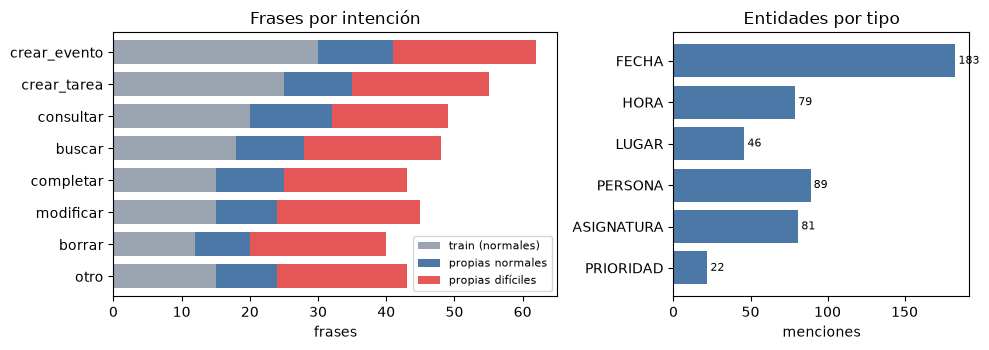

In [5]:
# Figura para la memoria: frases por intención (origen y dificultad) y entidades por tipo
ents_fig = Counter(e["tipo"] for x in corpus for e in x["entidades"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 2]})
grupos = pd.DataFrame({
    "train (normales)": df[df.origen == "train"].intencion.value_counts(),
    "propias normales": df[(df.origen == "propias") & ~df.dificil].intencion.value_counts(),
    "propias difíciles": df[df.dificil].intencion.value_counts(),
}).loc[INTENCIONES].fillna(0)
grupos.plot.barh(stacked=True, ax=a1, color=["#9aa5b1", "#4c78a8", "#e45756"], width=0.75)
a1.invert_yaxis(); a1.set_xlabel("frases"); a1.set_ylabel(""); a1.set_title("Frases por intención")
a1.legend(fontsize=8, loc="lower right")
a2.barh(TIPOS, [ents_fig[t] for t in TIPOS], color="#4c78a8")
a2.invert_yaxis(); a2.set_xlabel("menciones"); a2.set_title("Entidades por tipo")
for i, t in enumerate(TIPOS):
    a2.text(ents_fig[t] + 2, i, str(ents_fig[t]), va="center", fontsize=8)
fig.tight_layout(); fig.savefig("resultados/corpus.png", dpi=150)
plt.show()

In [6]:
from spacy.lang.es.stop_words import STOP_WORDS

def palabras(texto):
    return re.findall(r"\w+", texto.lower())

frec = Counter(w for t in df.texto for w in palabras(t))
n_tokens = sum(frec.values())
print(f"{n_tokens} palabras (tokens) · vocabulario: {len(frec)} tipos · TTR = {len(frec) / n_tokens:.2f}")
print("Hápax (aparecen una sola vez):", sum(c == 1 for c in frec.values()), f"({sum(c == 1 for c in frec.values()) / len(frec):.0%} del vocabulario)")
for origen in ("train", "propias"):
    f = Counter(w for t in df[df.origen == origen].texto for w in palabras(t))
    print(f"  {origen:<8} vocabulario {len(f)}")
nuevas = set(Counter(w for t in df[df.origen == "propias"].texto for w in palabras(t))) - set(Counter(w for t in df[df.origen == "train"].texto for w in palabras(t)))
print("Palabras de nuestras frases que no están en train:", len(nuevas), "· ej.:", sorted(nuevas)[:25])

3357 palabras (tokens) · vocabulario: 588 tipos · TTR = 0.18
Hápax (aparecen una sola vez): 267 (45% del vocabulario)
  train    vocabulario 324
  propias  vocabulario 509
Palabras de nuestras frases que no están en train: 264 · ej.: ['1205', '16', '24', '27', 'abre', 'aburrido', 'acordarme', 'acuarelas', 'acuerdo', 'alcalá', 'algebra', 'análisis', 'apetece', 'aplaza', 'arreglar', 'artificial', 'artículo', 'así', 'ay', 'ayuda', 'bar', 'basket', 'bbdd', 'biblio', 'bici']


In [7]:
def top_por_intencion(sin_stopwords, k=8):
    filas = {}
    for c in INTENCIONES:
        f = Counter(w for t in df[df.intencion == c].texto for w in palabras(t)
                    if not (sin_stopwords and w in STOP_WORDS))
        filas[c] = [f"{w} ({n})" for w, n in f.most_common(k)]
    return pd.DataFrame(filas).T

print("Palabras más frecuentes por intención, CON stopwords")
display(top_por_intencion(False))
print("Palabras más frecuentes por intención, SIN stopwords (lista de spaCy)")
display(top_por_intencion(True))

Palabras más frecuentes por intención, CON stopwords


,0,1,2,3,4,5,6,7
crear_evento,el (78),de (69),a (61),las (57),la (47),en (39),con (27),tengo (20)
crear_tarea,que (39),el (38),de (34),tengo (27),la (22),a (16),del (13),para (13)
consultar,tengo (30),qué (22),el (18),la (14),que (12),semana (10),de (9),algo (8)
buscar,de (27),la (25),cuándo (24),el (14),era (13),qué (13),a (12),tengo (10)
completar,ya (29),de (22),la (19),he (18),el (14),lo (14),del (7),que (6)
modificar,la (44),de (37),el (25),al (22),a (20),las (16),con (9),es (9)
borrar,de (31),la (27),lo (15),borra (13),el (13),del (10),quita (8),elimina (7)
otro,el (10),qué (8),es (7),a (5),de (5),un (4),tiempo (3),hacer (3)


Palabras más frecuentes por intención, SIN stopwords (lista de spaCy)


,0,1,2,3,4,5,6,7
crear_evento,mañana (11),9 (11),viene (10),media (9),semana (9),jueves (7),viernes (7),10 (6)
crear_tarea,comprar (8),urgente (7),prisa (6),mañana (6),semana (6),viene (6),q (6),recuérdame (5)
consultar,semana (10),mañana (6),dime (4),viene (4),libre (4),tareas (4),jueves (3),enséñame (3)
buscar,hora (8),pln (3),q (3),tutoría (2),javier (2),examen (2),estadística (2),cena (2)
completar,d (5),abuela (4),estadística (4),práctica (3),pln (3),regalo (3),matrícula (3),libros (3)
modificar,cambia (8),jueves (6),viernes (5),reunión (5),viene (5),mueve (4),12 (4),pasa (4)
borrar,borra (13),quita (8),elimina (7),suspendido (3),cancela (3),clase (3),lucía (3),partido (2)
otro,tiempo (3),mañana (3),vale (3),hola (2),gracias (2),cuéntame (2),hora (2),q (2)


**Comentario.** Con stopwords, las palabras más frecuentes son casi las mismas en todas las intenciones (*el, de, la, a, las*): no distinguen clases. Las pocas excepciones son justo stopwords con mucha información: *ya* y *he* en `completar`, *qué* en `consultar`, *cuándo* y *era* en `buscar`. Sin stopwords aparecen los verbos de acción que separan las clases (*borra/quita/elimina/cancela* en `borrar`; *cambia/mueve/pasa* en `modificar`; *comprar/urgente/prisa* en `crear_tarea`; *dime/libre/enséñame* en `consultar`), pero la lista de spaCy también borra *ya*, *qué* y *cuándo*. Por eso nuestra `normalizar` conserva esas palabras. Las abreviaturas *q* y *d* salen como palabras «de contenido»: sin expandir abreviaturas, un modelo de conteo las trata como palabras distintas de *que* y *de*.

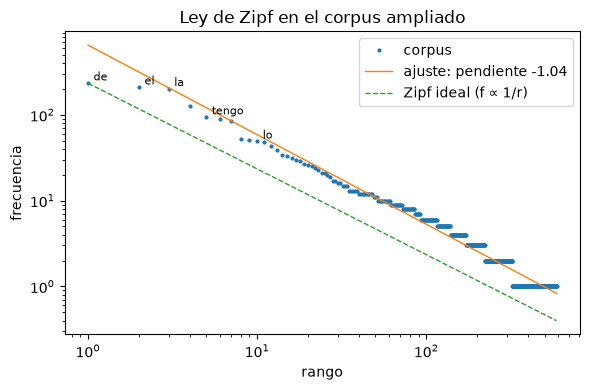

Pendiente log-log: -1.04 (Zipf predice ≈ -1)


In [8]:
import numpy as np

ranking = np.arange(1, len(frec) + 1)
frecuencias = np.array(sorted(frec.values(), reverse=True))
pendiente, ordenada = np.polyfit(np.log(ranking), np.log(frecuencias), 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ranking, frecuencias, ".", ms=4, label="corpus")
ax.loglog(ranking, np.exp(ordenada) * ranking ** pendiente, "-", lw=1, label=f"ajuste: pendiente {pendiente:.2f}")
ax.loglog(ranking, frecuencias[0] / ranking, "--", lw=1, label="Zipf ideal (f ∝ 1/r)")
for r in (1, 2, 3, 5, 10):
    w = frec.most_common(r)[-1][0]
    ax.annotate(w, (r, frec[w]), textcoords="offset points", xytext=(4, 2), fontsize=8)
ax.set_xlabel("rango"); ax.set_ylabel("frecuencia"); ax.set_title("Ley de Zipf en el corpus ampliado")
ax.legend(); fig.tight_layout(); fig.savefig("resultados/zipf.png", dpi=150)
plt.show()
print(f"Pendiente log-log: {pendiente:.2f} (Zipf predice ≈ -1)")

**Comentario.** La pendiente del ajuste log-log es ≈ −1,04, muy cerca de la ley de Zipf. La cola se aplana en escalones porque el corpus es pequeño: el 45 % del vocabulario son hápax (palabras que salen una sola vez). Esto anticipa el problema principal de los modelos de conteo (A2, A3): el test oculto traerá muchas palabras que no han visto nunca. Lo mitigan los n-gramas de caracteres (A3, robustos a faltas y abreviaturas) y los embeddings preentrenados (A5–A7).

In [9]:
def kwic(palabra, ventana=5, max_lineas=12):
    """Concordancias (Key Word In Context): `ventana` palabras a cada lado de cada aparición."""
    patron = re.compile(rf"\b{palabra}\b", re.I)
    lineas = []
    for x in corpus:
        for m in patron.finditer(x["texto"]):
            izq = " ".join(x["texto"][:m.start()].split()[-ventana:])
            der = " ".join(x["texto"][m.end():].split()[:ventana])
            lineas.append(f"{x['intencion']:<12} {izq:>40} [{m.group()}] {der}")
    print(f"--- «{palabra}»: {len(lineas)} apariciones")
    print("\n".join(lineas[:max_lineas]))

for w in ["mañana", "jueves", "finde", "semana que viene", "a las"]:
    kwic(w)

--- «mañana»: 30 apariciones
crear_evento                                          [mañana] a las 10 tengo dentista
crear_evento             cita en la peluquería pasado [mañana] a las 6 y media
crear_evento      Apúntame una videollamada con Pablo [mañana] a las 9 de la
crear_evento                                          [Mañana] desayuno con Andrea a las
crear_evento                    Tengo clase de inglés [mañana] a las 4 en la
crear_evento                                   Pasado [mañana] voy al cine con Marta
crear_tarea                  a la oferta de prácticas [mañana] , corre prisa
crear_tarea                los libros a la biblioteca [mañana] 
consultar                                  ¿Qué tengo [mañana] ?
consultar                             ¿Qué hay pasado [mañana] ?
consultar                 qué hora empieza lo primero [mañana] ?
consultar                   tengo el miércoles por la [mañana] ?
--- «jueves»: 21 apariciones
crear_evento                                   

In [10]:
# «mañana» = día siguiente (FECHA) frente a «por la mañana» / «de la mañana» (franja horaria)
apariciones = [(x["id"], m.start(), x) for x in corpus for m in re.finditer(r"\bmañana\b", x["texto"], re.I)]
def es_fecha(x, i):
    return any(e["tipo"] == "FECHA" and e["inicio"] <= i < e["fin"] for e in x["entidades"])
cuenta = Counter("FECHA" if es_fecha(x, i) else "otro sentido" for _, i, x in apariciones)
print("«mañana» en el corpus:", dict(cuenta))
for _, i, x in apariciones:
    if not es_fecha(x, i):
        print(f"  {x['id']} ({x['intencion']}): {x['texto']}")

«mañana» en el corpus: {'FECHA': 25, 'otro sentido': 5}
  tr073 (consultar): ¿Qué tengo el miércoles por la mañana?
  tr137 (otro): ¿Qué tiempo va a hacer mañana?
  g010 (crear_evento): El lunes que viene a las 8 de la mañana tengo análisis de sangre en el centro de salud
  g219 (otro): ¿A qué hora abre el Mercadona mañana?
  g223 (otro): Mañana es el cumple de Lucía, ¿qué le regalo?


**Comentario.** De las 30 apariciones de «mañana», 25 son la FECHA «día siguiente». Las otras 5 son la franja horaria («por la mañana», «a las 8 de la mañana») o frases `otro`, que por convención no llevan entidades aunque digan una fecha. Así que una regla «mañana → 2026-02-10» acierta casi siempre, pero tiene que mirar la palabra anterior (*la*). Los días de la semana salen a menudo dentro de expresiones más largas («el jueves de la semana que viene» = 19, no 12), así que el normalizador de fechas tiene que coger la expresión entera y no palabra a palabra. «a las» (77 veces) es un indicador casi seguro de HORA, pero el valor depende del contexto («cena a las 9» → 21:00).

In [11]:
ents = pd.json_normalize(corpus, record_path="entidades", meta=["id", "intencion", "dificil"])
ents["origen"] = ents.id.str[0].map({"t": "train", "g": "propias"})
print("Entidades por tipo y origen")
display(pd.crosstab(ents.tipo, ents.origen, margins=True, margins_name="total").loc[TIPOS + ["total"]])
print("Entidades por intención (media por frase)")
por_frase = pd.crosstab(ents.id, ents.tipo).reindex(df.id, fill_value=0)
por_frase["intencion"] = df.set_index("id").intencion
display(por_frase.groupby("intencion")[TIPOS].mean().round(2).loc[INTENCIONES])
print("Valores normalizados más frecuentes")
for t in ["FECHA", "HORA", "ASIGNATURA", "PRIORIDAD"]:
    print(f"  {t:<11}", dict(Counter(ents[ents.tipo == t].valor).most_common(8)))

Entidades por tipo y origen


origen,propias,train,total
tipo,,,
FECHA,109,74,183
HORA,45,34,79
LUGAR,28,18,46
PERSONA,55,34,89
ASIGNATURA,50,31,81
PRIORIDAD,14,8,22
total,301,199,500


Entidades por intención (media por frase)


tipo,FECHA,HORA,LUGAR,PERSONA,ASIGNATURA,PRIORIDAD
intencion,,,,,,
crear_evento,1.02,0.95,0.56,0.48,0.26,0.02
crear_tarea,0.71,0.00,0.02,0.27,0.38,0.38
consultar,0.84,0.06,0.00,0.06,0.06,0.00
buscar,0.04,0.00,0.04,0.21,0.27,0.00
completar,0.02,0.00,0.02,0.16,0.23,0.00
modificar,0.67,0.36,0.13,0.27,0.27,0.00
borrar,0.18,0.02,0.02,0.30,0.15,0.00
otro,0.00,0.00,0.00,0.00,0.00,0.00


Valores normalizados más frecuentes
  FECHA       {'2026-02-11': 25, '2026-02-10': 24, '2026-02-13': 17, '2026-02-12': 16, '2026-02-16': 12, '2026-02-09': 11, '2026-02-14': 10, '2026-02-19': 10}
  HORA        {'12:00': 9, '17:00': 7, '21:00': 7, '10:00': 6, '20:00': 5, '18:00': 5, '22:00': 5, '11:00': 4}
  ASIGNATURA  {'PLN': 20, 'Estadística': 16, 'Redes': 15, 'Bases de Datos': 11, 'Álgebra': 10, 'TFG': 9}
  PRIORIDAD   {'alta': 14, 'baja': 8}


**Comentario.** FECHA es con diferencia el tipo más frecuente (183 de 500 entidades) y PRIORIDAD el más raro (22). Como la métrica de B es F1 micro, el resultado dependerá sobre todo de resolver bien las fechas. Cada intención tiene un perfil propio: `crear_evento` lleva de media una FECHA y una HORA; `crear_tarea` casi nunca lleva HORA pero sí PRIORIDAD; `buscar`, `completar` y `borrar` casi no llevan entidades. Para esas tres, la tarea C tiene que apoyarse en las palabras de contenido («dentista», «matrícula») y no en las entidades.

## 1.3 Recursos lingüísticos (tema 2)
Tokenización, POS, lematización y NER con spaCy (`es_core_news_md`). Comparad las entidades de spaCy con vuestras etiquetas.

In [12]:
import spacy
nlp = spacy.load("es_core_news_md")

ejemplos = ["El jueves a las 5 tengo tutoría con Javier en el despacho 3204",
            "q tngo mñn x la mñn",
            "Ya he pagado la matrícula, márcalo como hecho"]
for t in ejemplos:
    doc = nlp(t)
    print(f"«{t}»  →  entidades spaCy: {[(e.text, e.label_) for e in doc.ents]}")
    display(pd.DataFrame([(tok.text, tok.pos_, tok.lemma_, tok.is_stop) for tok in doc],
                         columns=["token", "POS", "lema", "stopword"]).T)

«El jueves a las 5 tengo tutoría con Javier en el despacho 3204»  →  entidades spaCy: [('Javier', 'PER')]


,0,1,2,3,4,5,6,7,8,9,10,11,12
token,El,jueves,a,las,5,tengo,tutoría,con,Javier,en,el,despacho,3204
POS,DET,NOUN,ADP,DET,NUM,VERB,NOUN,ADP,PROPN,ADP,DET,NOUN,NUM
lema,el,jueves,a,el,5,tener,tutoría,con,Javier,en,el,despacho,3204
stopword,True,False,True,True,False,True,False,True,False,True,True,False,False


«q tngo mñn x la mñn»  →  entidades spaCy: [('q tngo mñn x', 'PER'), ('mñn', 'ORG')]


,0,1,2,3,4,5
token,q,tngo,mñn,x,la,mñn
POS,PROPN,PROPN,PROPN,PROPN,DET,PROPN
lema,q,tngo,mñn,x,el,mñn
stopword,False,False,False,False,True,False


«Ya he pagado la matrícula, márcalo como hecho»  →  entidades spaCy: [('márcalo', 'PER')]


,0,1,2,3,4,5,6,7,8
token,Ya,he,pagado,la,matrícula,",",márcalo,como,hecho
POS,ADV,AUX,VERB,DET,NOUN,PUNCT,ADJ,SCONJ,NOUN
lema,ya,haber,pagar,el,matrícula,",",márcalo,como,hecho
stopword,True,True,False,True,False,False,False,True,True


**Comentario.** Con texto estándar, spaCy acierta en lo importante: POS (*jueves* NOUN, *Javier* PROPN, *5* NUM), lemas (*tengo → tener*, *pagado → pagar*) y la persona. Con lenguaje de mensajería se rompe: en «q tngo mñn x la mñn» marca todos los tokens como PROPN y saca entidades sin sentido («q tngo mñn x» = PER). También falla con los clíticos: *márcalo* sale como PER y, como se ve en 1.4, lematiza *muévelo* como «muéveloir». Las frases de mensajería tienen que pasar antes por la normalización de abreviaturas.

In [13]:
# NER de spaCy frente a nuestras etiquetas. spaCy solo tiene PER, LOC, ORG y MISC:
# mapeamos PER → PERSONA y LOC → LUGAR y comparamos el texto con la misma normalización que evaluar.py.
from evaluar import _norm_texto

MAPA = {"PER": "PERSONA", "LOC": "LUGAR"}
docs = list(nlp.pipe(df.texto))
cnt = {t: Counter() for t in MAPA.values()}
otras_etiquetas = Counter()
fallos = []
for x, doc in zip(corpus, docs):
    oro = Counter((e["tipo"], _norm_texto(e["texto"])) for e in x["entidades"] if e["tipo"] in cnt)
    pred = Counter((MAPA[e.label_], _norm_texto(e.text)) for e in doc.ents if e.label_ in MAPA)
    otras_etiquetas.update((e.label_, e.text) for e in doc.ents if e.label_ not in MAPA)
    for k in set(oro) | set(pred):
        tp = min(oro[k], pred[k])
        cnt[k[0]].update(tp=tp, fp=pred[k] - tp, fn=oro[k] - tp)
        if pred[k] > tp: fallos.append(("FP", k[0], k[1], x["texto"]))
        if oro[k] > tp: fallos.append(("FN", k[0], k[1], x["texto"]))

filas = []
for t, c in cnt.items():
    p = c["tp"] / (c["tp"] + c["fp"]) if c["tp"] + c["fp"] else 0
    r = c["tp"] / (c["tp"] + c["fn"]) if c["tp"] + c["fn"] else 0
    filas.append({"tipo": t, "TP": c["tp"], "FP": c["fp"], "FN": c["fn"], "precisión": round(p, 2),
                  "exhaustividad": round(r, 2), "F1": round(2 * p * r / (p + r), 2) if p + r else 0})
display(pd.DataFrame(filas).set_index("tipo"))
print("Etiquetas de spaCy que no usamos (ORG/MISC):", Counter(l for l, _ in otras_etiquetas))
print("  ej.:", list(otras_etiquetas)[:12])

,TP,FP,FN,precisión,exhaustividad,F1
tipo,,,,,,
PERSONA,65,28,24,0.70,0.73,0.71
LUGAR,5,12,41,0.29,0.11,0.16


Etiquetas de spaCy que no usamos (ORG/MISC): Counter({'MISC': 39, 'ORG': 10})
  ej.: [('ORG', 'Bases de Datos'), ('MISC', 'Tengo'), ('MISC', 'Estadística'), ('MISC', 'Sol'), ('MISC', 'TFG'), ('MISC', 'Apúntame'), ('ORG', 'Laboratorio de Redes'), ('ORG', 'PLN'), ('MISC', 'Tutoría de PLN'), ('MISC', 'Redes'), ('MISC', 'Jurafsky'), ('MISC', 'Álgebra')]


In [14]:
fallos_df = pd.DataFrame(fallos, columns=["error", "tipo", "trozo", "frase"])
for (err, tipo), g in fallos_df.groupby(["error", "tipo"]):
    print(f"--- {err} {tipo}: {len(g)}  (FN = no lo detecta spaCy; FP = spaCy lo marca y no es)")
    print(g.head(8)[["trozo", "frase"]].to_string(index=False))
# spaCy no tiene tipos para FECHA, HORA, ASIGNATURA ni PRIORIDAD: esas entidades quedan todas sin detectar
print("\nEntidades sin equivalente en spaCy:", ents[~ents.tipo.isin(["PERSONA", "LUGAR"])].tipo.value_counts().to_dict())

--- FN LUGAR: 41  (FN = no lo detecta spaCy; FP = spaCy lo marca y no es)
          trozo                                                                                          frase
  despacho 3204                                 El jueves a las 5 tengo tutoría con Javier en el despacho 3204
     biblioteca             Pon una reunión con el grupo de Bases de Datos el martes a las 12 en la biblioteca
     aula magna                         El 20 de febrero es el examen de Estadística, a las 9 en el aula magna
            sol                                                 Quedada con Carlos el miércoles a las 7 en Sol
  polideportivo                                hoy a las 8 de la tarde tengo entrenamiento en el polideportivo
  despacho 4012 Reunión con Elena para el TFG el miércoles de la semana que viene a las 10 en el despacho 4012
centro de salud                                       Tengo médico el 17 a las 8 y media en el centro de salud
  laboratorio 2                       

**Comentario (alimenta B2).**
* **PERSONA (F1 ≈ 0,71):** spaCy detecta bien los nombres propios con mayúscula (*Javier, Marta, Elena*). Falla en los **parentescos** («madre», «abuela», «hermana»: son nombres comunes), en los **nombres en minúscula** de las frases de mensajería («lucia», «carlos») y da falsos positivos con verbos en mayúscula al principio de la frase (*Tacha*, *Adiós*, *porfa*) y con empresas o restaurantes (*Indra*, *Lhardy*).
* **LUGAR (F1 ≈ 0,16):** nuestros lugares son sobre todo **nombres comunes con número** («despacho 3204», «biblioteca», «polideportivo», «aula magna»), que no son topónimos, así que spaCy casi nunca los marca como LOC. Lo que marca como LOC son nombres propios sueltos (*Australia*, *Vitalia*, *Alcalá* sin «calle») o palabras que no son lugares (*Estadística*, *IA*).
* Las asignaturas salen como **ORG/MISC** («Bases de Datos», «PLN», «Redes») y **no hay nada para FECHA, HORA ni PRIORIDAD**.

Conclusión para B2: usar spaCy para PERSONA, completado con una lista de parentescos, y para LUGAR mejor reglas («en el/la X», «despacho/aula/laboratorio + número») que el LOC de spaCy. El resto, con las reglas de B1.

## 1.4 Preprocesado (tema 3)
Una función de normalización configurable. Cuando funcione, **copiadla a `utilidades.py`** para usarla en los demás notebooks (se necesita en el experimento E2).

La función ya está en `utilidades.py` (la mostramos aquí con `inspect`). Decisiones:
* **Tildes**: se quitan tildes y diéresis pero **se conserva la ñ** («mañana» ≠ «manana» en español).
* **Abreviaturas**: diccionario de mensajería (`q`, `tngo`, `mñn`, `xq`, `x`, `d`, `finde`, `bbdd`…). No incluimos «a» ni «e», que son palabras normales.
* **Números con letras**: «cinco» → 5, «veintitrés» → 23; «una» solo en «la una» (si no, «una reunión» → «1 reunión»).
* **Stopwords**: lista de spaCy **menos** las que importan aquí: negaciones (`no`, `ni`, `nunca`, `ya`, `sin`), interrogativos (`qué`, `cuándo`, `dónde`), palabras temporales (`hoy`, `mañana`, `tarde`, `antes`, `pasado`, `dentro`, `día`, `semana`) y números con letras (spaCy considera stopword «cinco»).
* **Raíz**: `raiz="stem"` (Snowball español de NLTK) o `raiz="lema"` (spaCy).

In [15]:
import inspect, utilidades
print(inspect.getsource(utilidades.normalizar))

def normalizar(texto, minusculas=True, quitar_tildes=False, abreviaturas=False, numeros=False,
               quitar_stopwords=False, raiz=None):
    """Normalización configurable (se usa en E2, C1 y el asistente).

    minusculas      : pasa a minúsculas.
    quitar_tildes   : quita tildes/diéresis (conserva la ñ).
    abreviaturas    : expande abreviaturas de mensajería («q tngo mñn» → «que tengo mañana»).
    numeros         : números con letras → cifras («a las cinco» → «a las 5», «la una» → «la 1»).
    quitar_stopwords: quita stopwords de spaCy salvo las de CONSERVAR (no, ya, hoy, qué, cuándo...).
    raiz            : None, "stem" (Snowball español) o "lema" (lematización de spaCy).
    Si solo se piden minúsculas/tildes se devuelve el texto tal cual; si no, los tokens unidos por espacios.
    """
    t = texto.lower() if minusculas else texto
    if not (abreviaturas or numeros or quitar_stopwords or raiz):
        return sin_tildes(t) if quitar_tildes else t

    toks = tokeni

In [16]:
configs = {
    "original": dict(minusculas=False),
    "minúsculas + tildes": dict(quitar_tildes=True),
    "abreviaturas + números": dict(abreviaturas=True, numeros=True),
    "sin stopwords": dict(abreviaturas=True, numeros=True, quitar_stopwords=True),
    "stemming": dict(abreviaturas=True, numeros=True, quitar_stopwords=True, raiz="stem"),
    "lematización": dict(abreviaturas=True, numeros=True, raiz="lema"),
}
pruebas = ["q tngo mñn??", "El viernes ceno con Andrea a las nueve", "No borres el dentista, muévelo a la una",
           "TENGO QUE ENTREGAR EL INFORME DE BBDD", "Ya he pagado la matrícula"]
pd.DataFrame({nombre: [normalizar(t, **cfg) for t in pruebas] for nombre, cfg in configs.items()}, index=pruebas).T

,q tngo mñn??,El viernes ceno con Andrea a las nueve,"No borres el dentista, muévelo a la una",TENGO QUE ENTREGAR EL INFORME DE BBDD,Ya he pagado la matrícula
original,q tngo mñn??,El viernes ceno con Andrea a las nueve,"No borres el dentista, muévelo a la una",TENGO QUE ENTREGAR EL INFORME DE BBDD,Ya he pagado la matrícula
minúsculas + tildes,q tngo mñn??,el viernes ceno con andrea a las nueve,"no borres el dentista, muevelo a la una",tengo que entregar el informe de bbdd,ya he pagado la matricula
abreviaturas + números,que tengo mañana ? ?,el viernes ceno con andrea a las 9,"no borres el dentista , muévelo a la 1",tengo que entregar el informe de bases de datos,ya he pagado la matrícula
sin stopwords,que tengo mañana ? ?,viernes ceno andrea 9,"no borres dentista , muévelo 1",tengo que entregar informe bases datos,ya pagado matrícula
stemming,que teng mañan ? ?,viern cen andre 9,"no borr dentist , muevel 1",teng que entreg inform bas dat,ya pag matricul
lematización,que tener mañana ? ?,el viernes ceno con andrea a el 9,"no borrar el dentista , muéveloir a el 1",tener que entregar el informe de base de dato,ya haber pagar el matrícula


In [17]:
# Efecto sobre el vocabulario del corpus (menos tipos = menos dispersión para los modelos de conteo)
filas = []
for nombre, cfg in configs.items():
    if nombre == "lematización":
        continue  # lenta con spaCy; no hace falta para el resumen
    toks = [w for t in df.texto for w in utilidades.tokenizar(normalizar(t, **cfg)) if re.match(r"\w", w)]
    filas.append({"configuración": nombre, "tokens": len(toks), "vocabulario": len(set(toks))})
pd.DataFrame(filas).set_index("configuración")

,tokens,vocabulario
configuración,,
original,3356,706
minúsculas + tildes,3356,569
abreviaturas + números,3374,551
sin stopwords,1903,475
stemming,1903,387


**Comentario.** Cada paso reduce el vocabulario: de 706 tipos en el texto original a 569 con minúsculas y sin tildes, 551 expandiendo abreviaturas y números, 475 sin stopwords y 387 con stemming (−45 %). Menos tipos significa matrices de conteo menos dispersas, lo que debería ayudar a A2 y A3 (lo comprobaremos en E2). El precio: el stemming junta palabras distintas (*cena/ceno → cen*) y los lemas de spaCy fallan con los clíticos (*muévelo*). Además, un modelo Transformer (A6) espera texto natural, así que es posible que el texto «roto» por el preprocesado le perjudique.

## 1.5 Entrenamiento y validación
Se separa una sola vez y se guarda: **todos** los notebooks usan estas mismas particiones. La validación no se usa nunca para entrenar.

Estratificamos por **intención y dificultad** (no solo por intención, como hacía la plantilla) para que la validación tenga la misma proporción de frases difíciles que el corpus y alcance las 30 que pide E3. Si los ficheros ya existen no se regeneran (poner `REGENERAR = True` solo si se cambia el corpus antes de empezar las fases siguientes).

In [18]:
from sklearn.model_selection import train_test_split

REGENERAR = False
if REGENERAR or not (os.path.exists("mi_train.jsonl") and os.path.exists("mi_validacion.jsonl")):
    tr, val = train_test_split(corpus, test_size=0.2, random_state=0,
                               stratify=[f'{x["intencion"]}|{x["dificil"]}' for x in corpus])
    guardar(tr, "mi_train.jsonl")
    guardar(val, "mi_validacion.jsonl")
    print("Particiones generadas y guardadas")
else:
    tr, val = cargar("mi_train.jsonl"), cargar("mi_validacion.jsonl")
    assert {x["id"] for x in tr} | {x["id"] for x in val} == {x["id"] for x in corpus}, "el corpus ha cambiado"
    print("Particiones cargadas de disco (no se regeneran)")

assert not {x["id"] for x in tr} & {x["id"] for x in val}
assert sum(x["dificil"] for x in val) >= 30
print(len(tr), "entrenamiento ·", len(val), "validación ·", sum(x["dificil"] for x in val), "difíciles en validación")

Particiones cargadas de disco (no se regeneran)
308 entrenamiento · 77 validación · 31 difíciles en validación


In [19]:
part = pd.DataFrame([{"partición": p, "intencion": x["intencion"], "dificil": x["dificil"], "dificultad": x.get("dificultad", "normal")}
                     for p, xs in (("train", tr), ("validación", val)) for x in xs])
display(pd.crosstab(part.intencion, [part["partición"], part.dificil]).loc[INTENCIONES])
print("Tipos de dificultad en validación:", part[part["partición"] == "validación"].dificultad.value_counts().to_dict())
print("Frases con ref en validación (tarea C):", sum(1 for x in val if x["ref"]))

partición    train       validación      
dificil      False True       False True 
intencion                                
crear_evento    33    17          8     4
crear_tarea     28    16          7     4
consultar       26    14          6     3
buscar          22    16          6     4
completar       20    14          5     4
modificar       19    17          5     4
borrar          16    16          4     4
otro            19    15          5     4

Tipos de dificultad en validación: {'normal': 46, 'parafrasis': 6, 'ortografia': 5, 'numeros_letras': 4, 'fecha_relativa': 3, 'negacion': 3, 'abreviatura': 3, 'fuera_dominio': 2, 'mayusculas': 2, 'larga': 2, 'contexto': 1}
Frases con ref en validación (tarea C): 36
